In [1]:
import gzip
import pickle
import numpy as np
import matplotlib.pyplot as plt 
import random       
import pandas as pd

In [2]:
f = gzip.open('../Data/mnist.pkl.gz', 'rb')
training_data, validation_data, test_data = pickle.load(f, encoding="latin1")
f.close()

In [3]:
def vectorized_result(j):
    """Return a 10-dimensional unit vector with a 1.0 in the jth
    position and zeroes elsewhere.  This is used to convert a digit
    (0...9) into a corresponding desired output from the neural
    network."""
    e = np.zeros((10, 1))
    e[j] = 1.0
    return e
def sigmoid_prime(z):
    """Derivative of the sigmoid function."""
    return sigmoid(z)*(1-sigmoid(z))
def sigmoid(t):
    return 1/(1+np.exp(-t))
def evaluate(y_preds, y_target):
    # calculate the number of correct guesses in y_preds compared to the 
    # targets in y_target.
    num = sum([np.argmax(a) == np.argmax(b) for a,b in zip(y_preds, y_target)])
    return (num) 
def forward_pass(Weight, bias, x):
    for w, b in zip(Weight, bias):
        x = sigmoid(w @ x + b)
    return (x)

In [4]:
def relu(t, alpha = 0.01): #Leaky in reality 
    return np.where(t>0, t,alpha*t)

def relu_prime(z, alpha = 0.01):
    return np.where(z > 0, 1, alpha)

def forward_pass(Weight, bias, x):
    for w, b in zip(Weight, bias):
        x = relu(w @ x + b)
    return (x)


In [5]:
training_results = [vectorized_result(y) for y in training_data[1]]
training_inputs = [np.reshape(x, (784, 1)) for x in training_data[0]]
print(len(training_inputs), type(training_results), type(training_results))

50000 <class 'list'> <class 'list'>


In [6]:
#sample_idx = np.random.choice(len(training_inputs), size=100, replace=False)

#training_inputs_sample  = [training_inputs[i] for i in sample_idx]
#training_results_sample = [training_results[i] for i in sample_idx]
#print(len(training_inputs_sample), type(training_results_sample), type(training_results_sample))

https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html

In [7]:
#import os
import torch
#from torch import nn
#from torch.utils.data import DataLoader
#from torchvision import datasets, transforms

In [8]:
def backpropagation(bias, Weight, num_layers, x, y):
    nabla_b = [np.zeros(len(b)) for b in bias]
    nabla_w = [np.zeros_like(w) for w in Weight]
    # feedforward
    act = x
    act_list = [x] # store all activations layer-by-layer
    zs = [] # list to store all the z vectors, layer by layer
    for w, b in zip(Weight, bias):
        z = (w @ act + b)
        zs.append(z)
        act = relu(z)
        act_list.append(act)
    # backward pass:
    delta = relu_prime(zs[-1]) * (act_list[-1] - y)
    nabla_b[-1] = delta
    nabla_w[-1] = delta @ act_list[-2].T
    for l in range(2, num_layers):
        z = zs[-l]
        sp = relu_prime(z)
        delta = np.dot(Weight[-l+1].transpose(), delta) * sp
        nabla_b[-l] = delta
        nabla_w[-l] = delta @ act_list[-l-1].T
    return (nabla_b, nabla_w)

In [9]:
N = 1000
N_2 = 1000
N_3 = 100

In [10]:
layers = [784,N, 10] #input layer, hidden layer(s), output layer
#initiate weights
num_layers = len(layers)
# running a single epoch consisting of all training examples

# initiating bias and weighs
bias = []
Weight = []
for i, j in zip(layers,layers[1:]):
    bias.append(np.random.randn(j,1)) # a random bias with j rows and 1 col
    Weight.append(np.random.randn(j, i) * np.sqrt(2.0 / i))  # a random Weight matrix with j rows and i cols, scaled to work with relu

cost = []
eta = 0.02 # learn rate
table = [] # for storing
##Start of Epoch loop
NUM_EPOCHS = 200

for epoch in range(NUM_EPOCHS):
    if epoch > 75:
        eta = 0.005
    elif epoch > 50:
        eta = 0.01
        
    sample_idx = np.random.choice(len(training_inputs), size=100, replace=False)
    #rng.shuffle(sample_idx)
    for i in sample_idx:
        x = training_inputs[i]
        y = training_results[i]
        #print(i)

    # feedforward
        act = x
        act_list = [x] # store all activations layer-by-layer
        zs = [] # list to store all the z vectors, layer by layer
        for w, b in zip(Weight, bias):
            z = w @ act + b
            zs.append(z)
            act = relu(z )
            act_list.append(act)

    # get the gradients nabla_b and nabla_w for each layer based on the training example
        nabla_b, nabla_w = backpropagation(bias, Weight, num_layers, x, y)
        Weight = [w-eta*nw for w, nw in zip(Weight, nabla_w)]
        bias = [b-eta*nb for b, nb in zip(bias, nabla_b)]
    y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]
    correct_prop_test = evaluate(y_preds, training_results)/len(training_results)
    table.append({"epoch": epoch + 1,"accuracy": correct_prop_test, "eta": eta})
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Accuracy: {correct_prop_test:.4f}")

Epoch 1/200 — Accuracy: 0.0776
Epoch 2/200 — Accuracy: 0.1164
Epoch 3/200 — Accuracy: 0.1280
Epoch 4/200 — Accuracy: 0.1767
Epoch 5/200 — Accuracy: 0.2088
Epoch 6/200 — Accuracy: 0.2536
Epoch 7/200 — Accuracy: 0.2487
Epoch 8/200 — Accuracy: 0.2378
Epoch 9/200 — Accuracy: 0.1398
Epoch 10/200 — Accuracy: 0.2464
Epoch 11/200 — Accuracy: 0.2775
Epoch 12/200 — Accuracy: 0.2933
Epoch 13/200 — Accuracy: 0.2895
Epoch 14/200 — Accuracy: 0.3046
Epoch 15/200 — Accuracy: 0.3552
Epoch 16/200 — Accuracy: 0.3795
Epoch 17/200 — Accuracy: 0.3555
Epoch 18/200 — Accuracy: 0.3330
Epoch 19/200 — Accuracy: 0.4073
Epoch 20/200 — Accuracy: 0.4658
Epoch 21/200 — Accuracy: 0.4672
Epoch 22/200 — Accuracy: 0.5007
Epoch 23/200 — Accuracy: 0.5518
Epoch 24/200 — Accuracy: 0.5372
Epoch 25/200 — Accuracy: 0.5742
Epoch 26/200 — Accuracy: 0.5189
Epoch 27/200 — Accuracy: 0.5507
Epoch 28/200 — Accuracy: 0.5997
Epoch 29/200 — Accuracy: 0.6040
Epoch 30/200 — Accuracy: 0.5639
Epoch 31/200 — Accuracy: 0.6169
Epoch 32/200 — Ac

Me habia equivocado a la hora de escribir el codigo del bucle después de hacer el sample, pero tras descubrir el error, he encontrado una manera de entrenar con 100 resultados diferentes cada una de las etapas. Consiguiendo un mejor resultado y además más fiable 

In [11]:
test_results = [vectorized_result(y) for y in test_data[1]]
test_inputs = [np.reshape(x, (784, 1)) for x in test_data[0]]

In [12]:
y_preds = [forward_pass(Weight, bias, x) for x in test_inputs]
correct_prop_test = evaluate(y_preds, test_results)/len(test_results)

In [13]:
correct_prop_test

np.float64(0.9258)

<Axes: xlabel='epoch', ylabel='accuracy'>

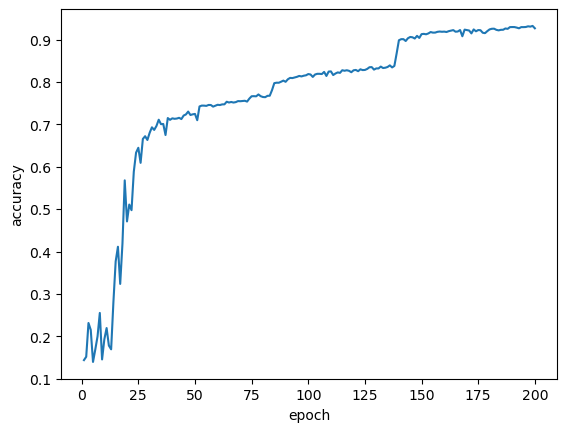

In [149]:
import seaborn as sns
table = pd.DataFrame(table)
sns.lineplot(data=table, x="epoch", y="accuracy")

https://arxiv.org/pdf/2001.08361

In [15]:
rng = np.random.default_rng()      # initiate random
ix_example = np.arange(len(training_inputs))     # array [0,1,...,N]
rng.shuffle(ix_example) 

In [ ]:
len(ix_example)


50000

In [16]:
layers = [784,N, 10] #input layer, hidden layer(s), output layer
#initiate weights
num_layers = len(layers)
# running a single epoch consisting of all training examples

# initiating bias and weighs
bias = []
Weight = []
for i, j in zip(layers,layers[1:]):
    bias.append(np.random.randn(j,1)) # a random bias with j rows and 1 col
    Weight.append(np.random.randn(j, i) * np.sqrt(2.0 / i))  # a random Weight matrix with j rows and i cols, scaled to work with relu

cost = []
eta = 0.02 # learn rate
table = [] # for storing
##Start of Epoch loop
NUM_EPOCHS = 2

for epoch in range(NUM_EPOCHS):
    if epoch > 75:
        eta = 0.005
    elif epoch > 50:
        eta = 0.01
        
    
    rng.shuffle(ix_example)
    for i in ix_example:
        x = training_inputs[i]
        y = training_results[i]

    # feedforward
        act = x
        act_list = [x] # store all activations layer-by-layer
        zs = [] # list to store all the z vectors, layer by layer
        for w, b in zip(Weight, bias):
            z = w @ act + b
            zs.append(z)
            act = relu(z )
            act_list.append(act)

    # get the gradients nabla_b and nabla_w for each layer based on the training example
        nabla_b, nabla_w = backpropagation(bias, Weight, num_layers, x, y)
        Weight = [w-eta*nw for w, nw in zip(Weight, nabla_w)]
        bias = [b-eta*nb for b, nb in zip(bias, nabla_b)]
    y_preds = [forward_pass(Weight, bias, x) for x in training_inputs]
    correct_prop_test = evaluate(y_preds, training_results)/len(training_results)
    table.append({"epoch": epoch + 1,"accuracy": correct_prop_test, "eta": eta})
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} — Accuracy: {correct_prop_test:.4f}")

Epoch 1/2 — Accuracy: 0.9741
Epoch 2/2 — Accuracy: 0.9859


In [17]:
y_preds = [forward_pass(Weight, bias, x) for x in test_inputs]
correct_prop_test = evaluate(y_preds, test_results)/len(test_results)

In [18]:
correct_prop_test

np.float64(0.9755)